In [26]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.model_selection import cross_val_score, StratifiedKFold

In [27]:
#Data loading
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

display(train.head())
display(test.head())

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [28]:
#Data cleaning
df = train.copy()
test_df = test.copy()

for data in [df, test_df]:
    for col in data.columns:
        if data[col].dtype == object or str(data[col].dtype) in ["str", "string", "category"]:
            data[col] = data[col].apply(lambda x: x.strip() if isinstance(x, str) else x)
            data[col] = data[col].replace("", np.nan)

print("Train shape:", df.shape)
print("Test shape:", test_df.shape)

Train shape: (614, 13)
Test shape: (367, 12)


In [29]:
display(df.head())
df.info()
display(df.describe(include="all").T)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Loan_ID,614,614,LP001002,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,601,2,Male,489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,611,2,Yes,398,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,599,4,0,345,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education,614,2,Graduate,480,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Self_Employed,582,2,No,500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ApplicantIncome,614.0,NaN,NaN,NaN,5403.459283,6109.041673,150.0,2877.5,3812.5,5795.0,81000.0
CoapplicantIncome,614.0,NaN,NaN,NaN,1621.245798,2926.248369,0.0,0.0,1188.5,2297.25,41667.0
LoanAmount,592.0,NaN,NaN,NaN,146.412162,85.587325,9.0,100.0,128.0,168.0,700.0
Loan_Amount_Term,600.0,NaN,NaN,NaN,342.0,65.12041,12.0,360.0,360.0,360.0,480.0


In [30]:
#misssing value 
print("Duplicate rows:", df.duplicated().sum())
print("Missing values in train:")
display(df.isna().sum().to_frame("Missing Values"))

print("Missing values in test:")
display(test_df.isna().sum().to_frame("Missing Values"))

df = df.drop_duplicates().reset_index(drop=True)
df = df.dropna(subset=["Loan_Status"]).copy()

Duplicate rows: 0
Missing values in train:


,Missing Values
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


Missing values in test:


,Missing Values
Loan_ID,0
Gender,11
Married,0
Dependents,10
Education,0
Self_Employed,23
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,5
Loan_Amount_Term,6


In [31]:
#Featuer type
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [
    col for col in df.columns
    if col not in numeric_cols
]

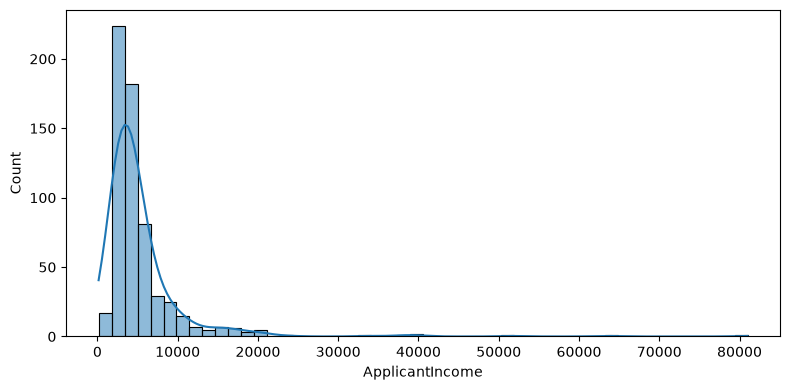

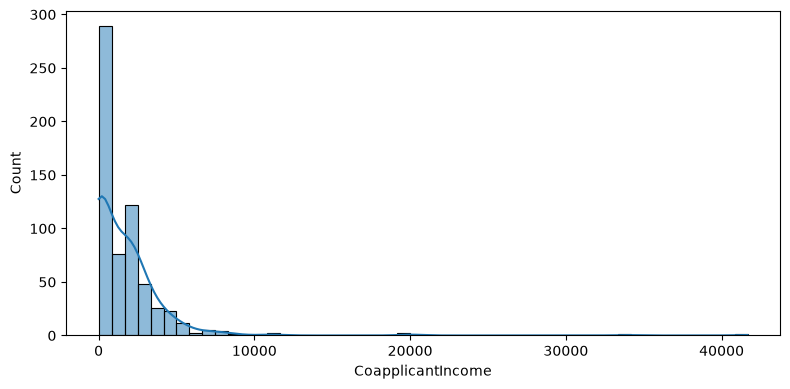

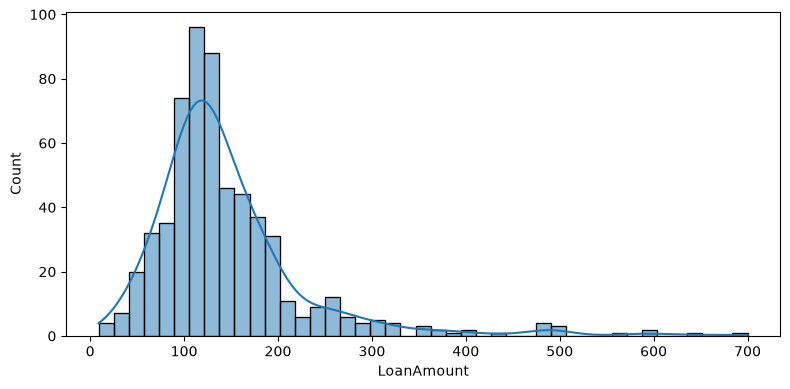

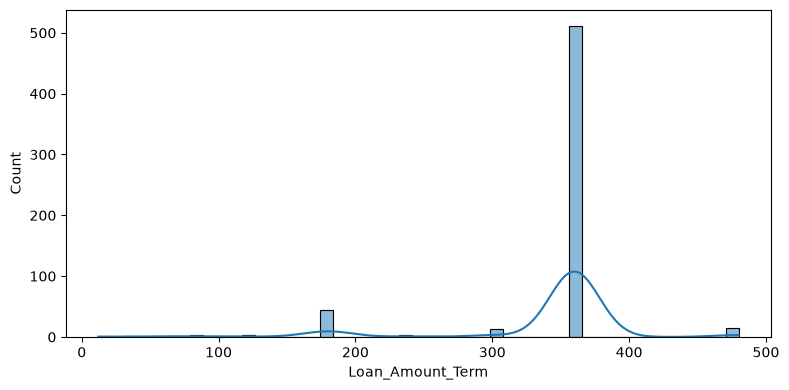

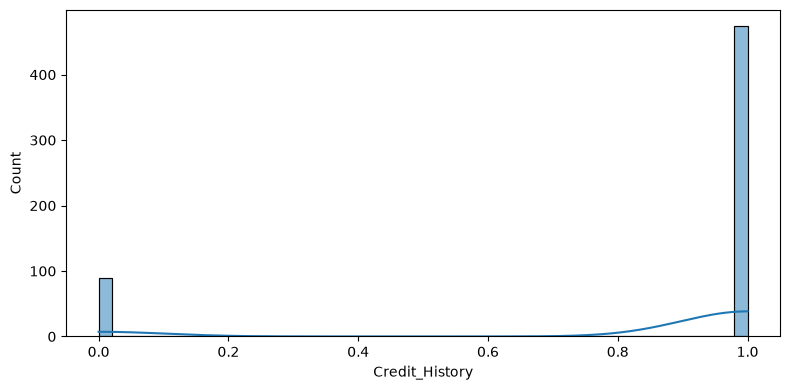

In [32]:
# Histogram
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.tight_layout()
    plt.show()

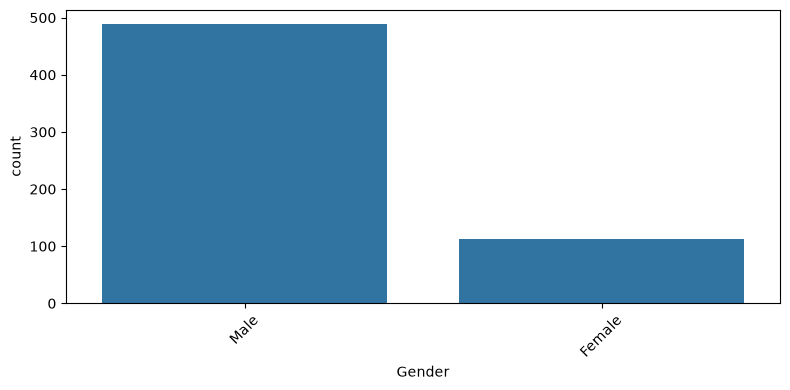

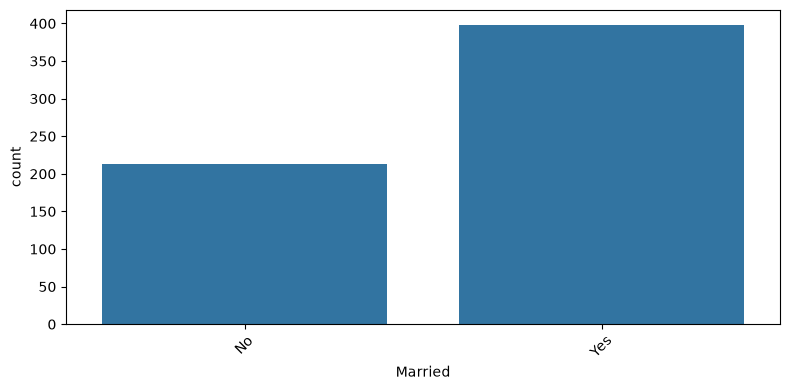

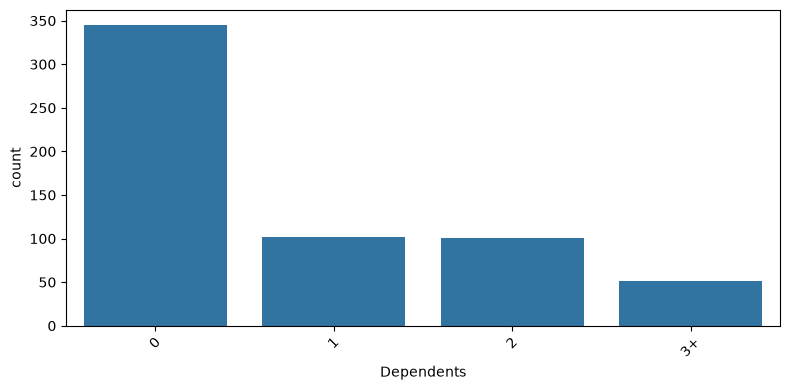

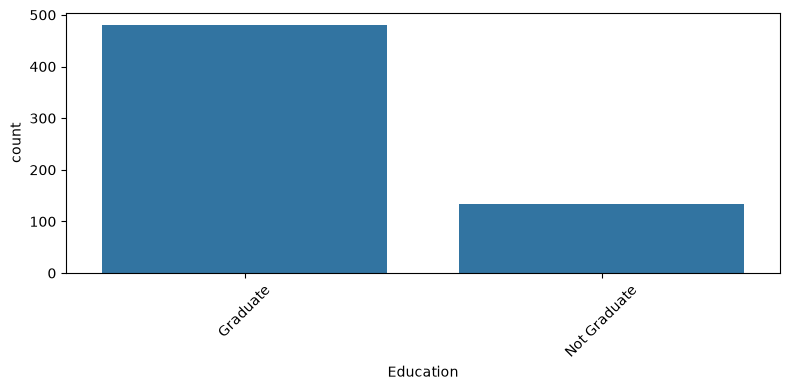

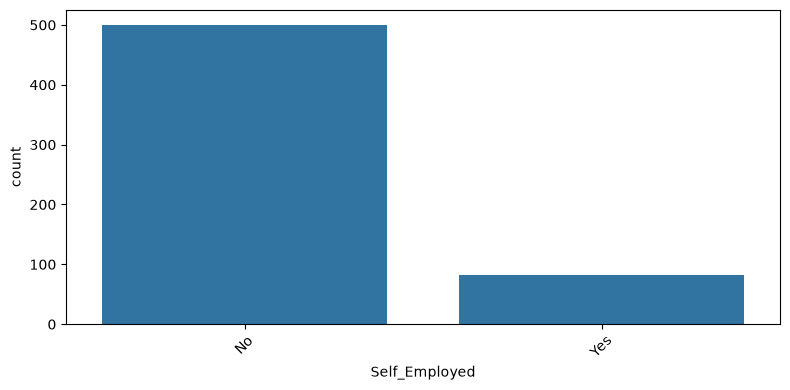

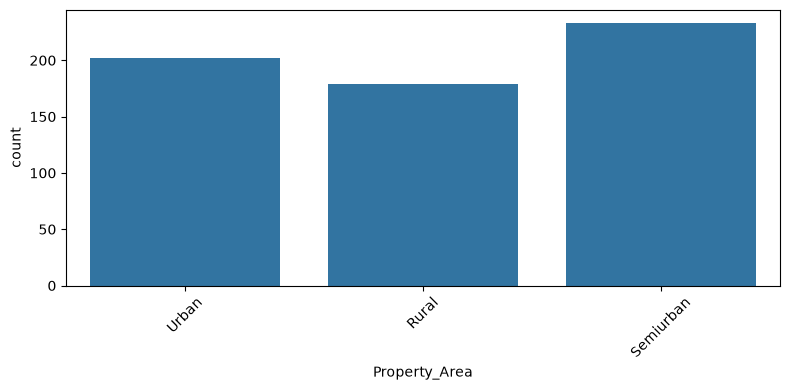

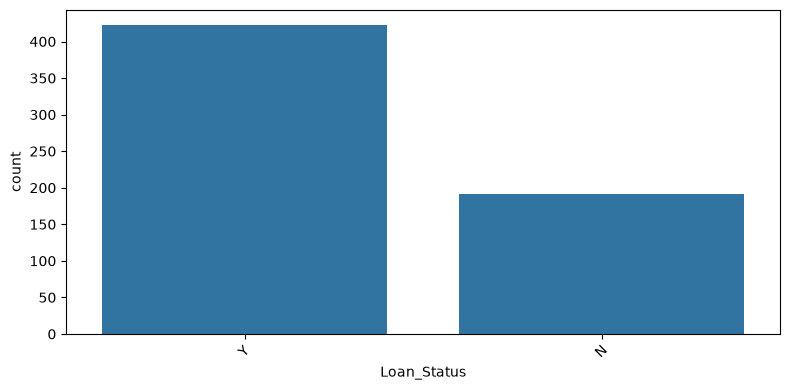

In [33]:
#Countplots
for col in categorical_cols:
    if df[col].nunique(dropna=True) <= 20:
        plt.figure(figsize=(8, 4))
        sns.countplot(data=df, x=col)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

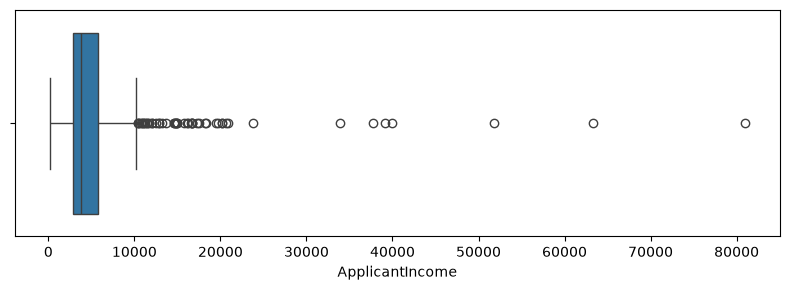

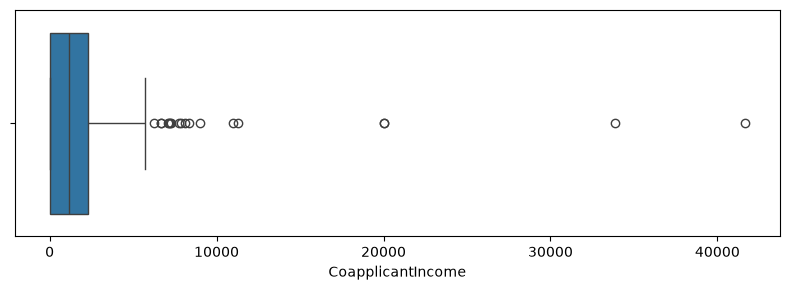

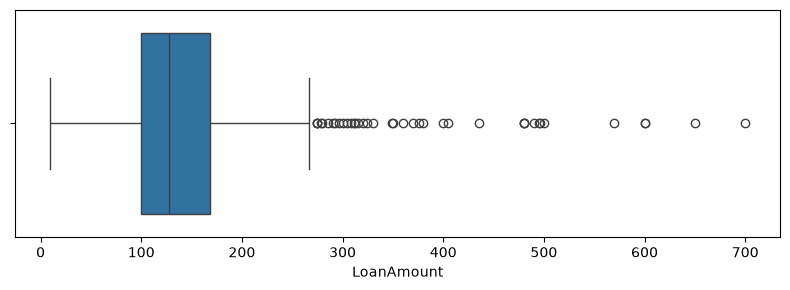

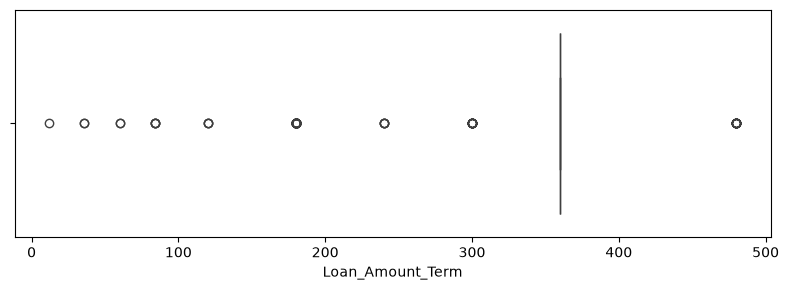

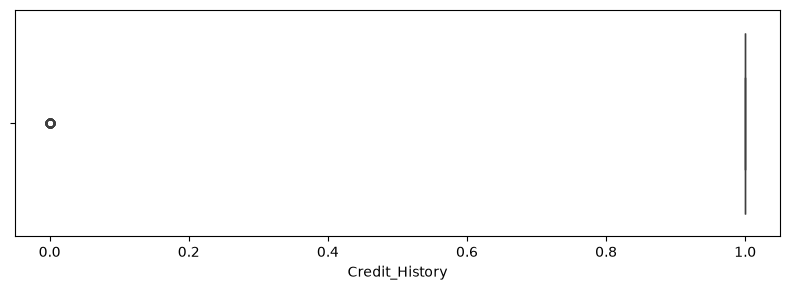

In [34]:
#Boxplot
for col in numeric_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(data=df, x=col)
    plt.tight_layout()
    plt.show()


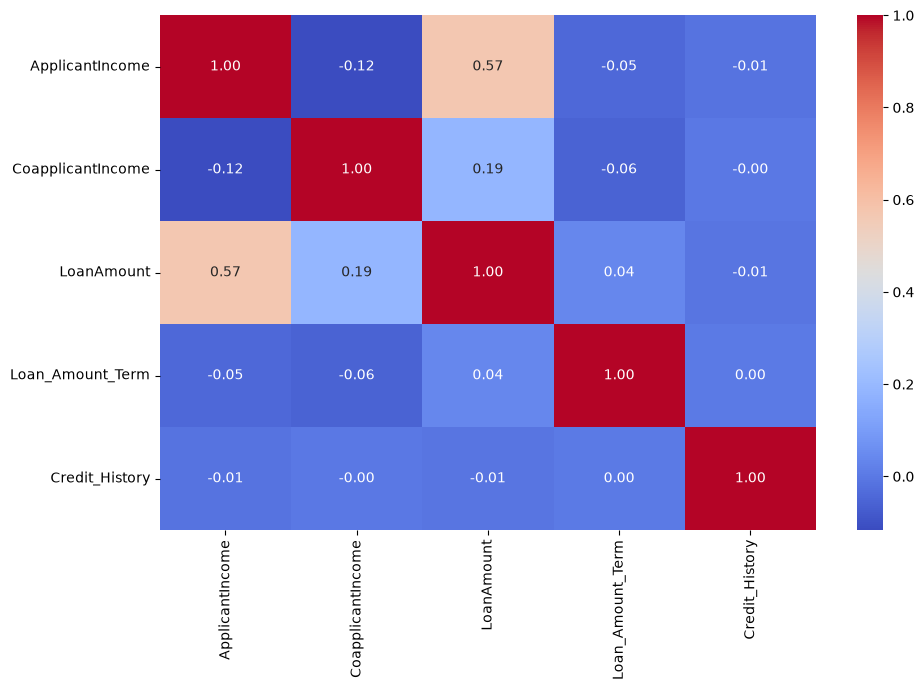

In [35]:
#Correlation Heatmap

if len(numeric_cols) >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
    plt.tight_layout()
    plt.show()

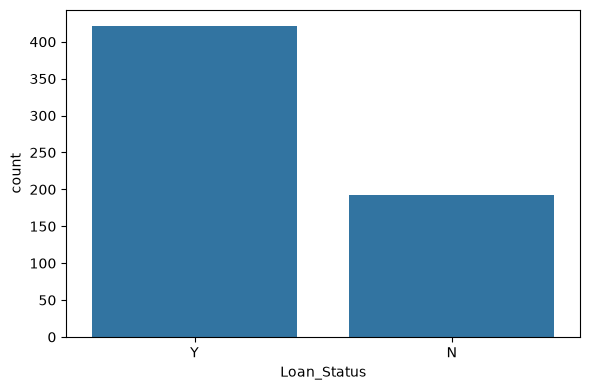

Loan_Status
Y    422
N    192
Name: count, dtype: int64

In [36]:
#Target Distribution

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Loan_Status")
plt.tight_layout()
plt.show()
display(df["Loan_Status"].value_counts(dropna=False))

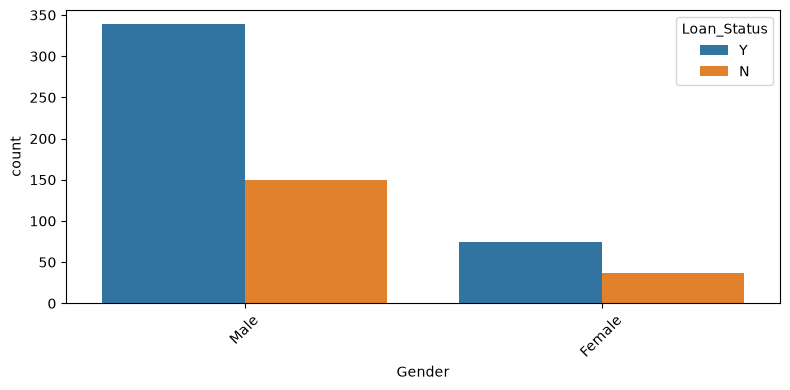

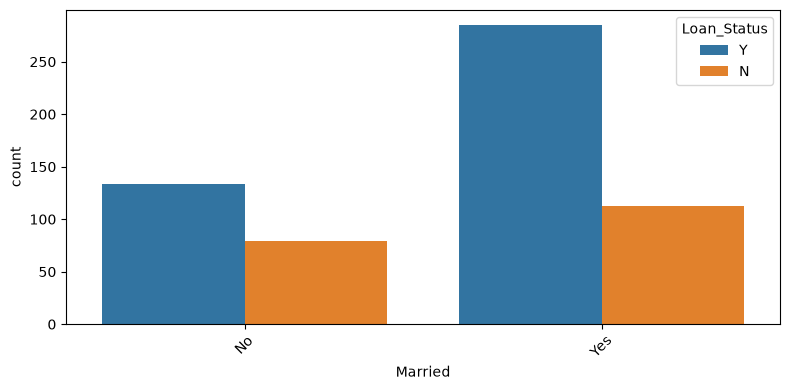

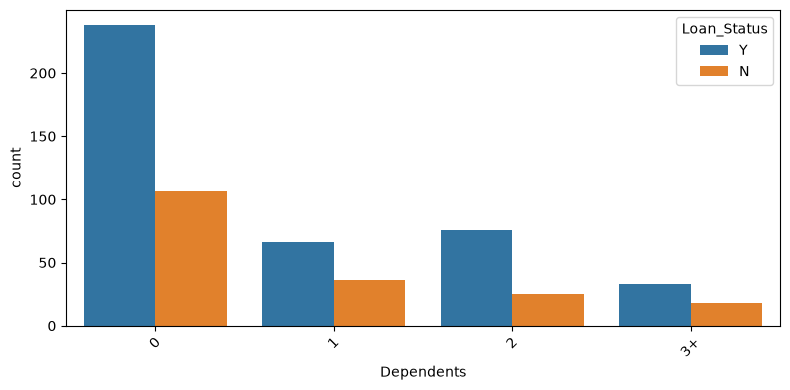

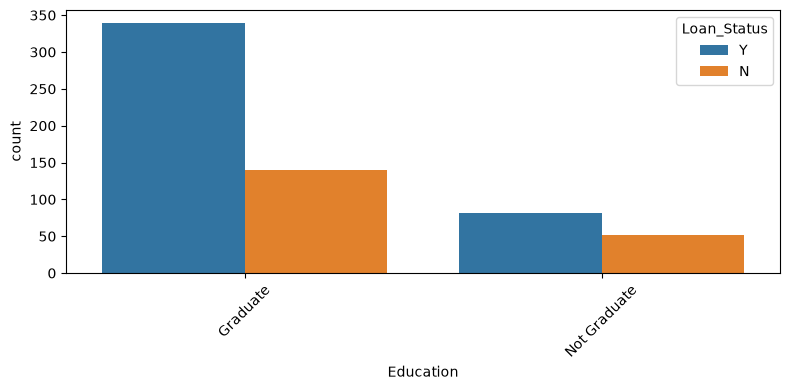

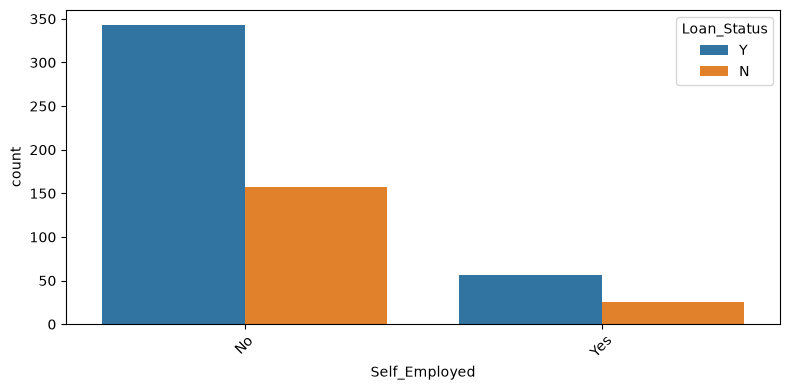

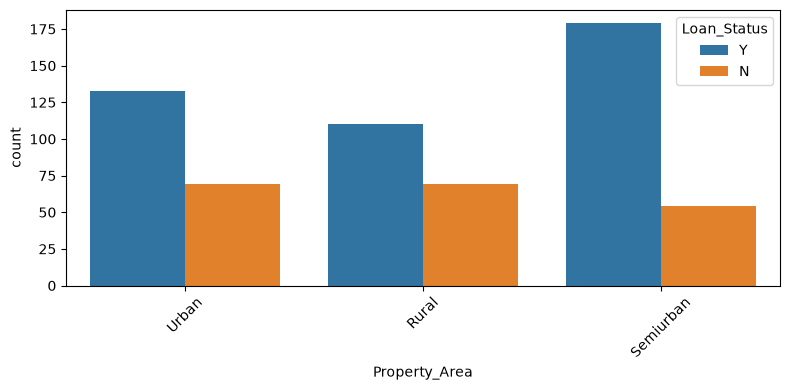

In [37]:
#Target distribution
for col in categorical_cols:
    if col not in ["Loan_Status", "Loan_ID"] and df[col].nunique(dropna=True) <= 20:
        plt.figure(figsize=(8, 4))
        sns.countplot(data=df, x=col, hue="Loan_Status")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

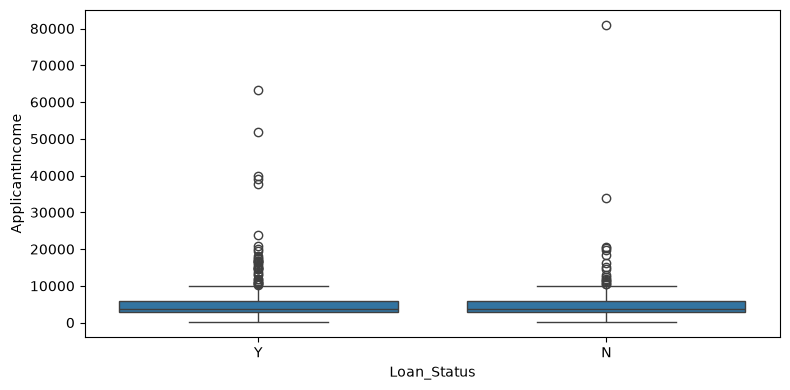

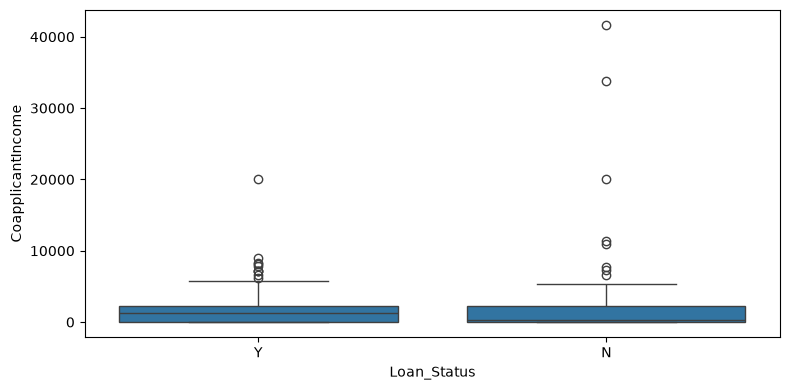

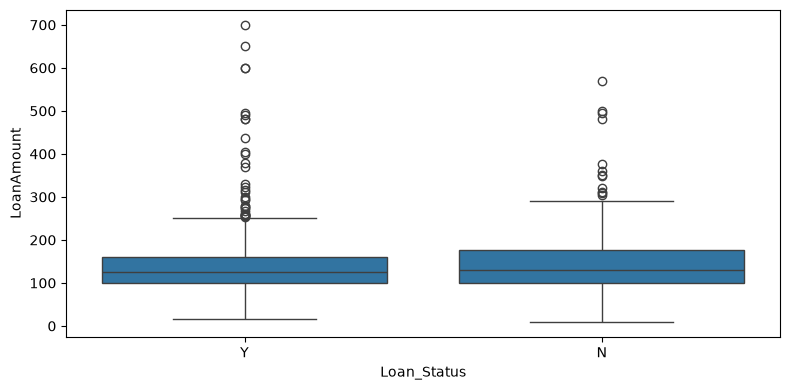

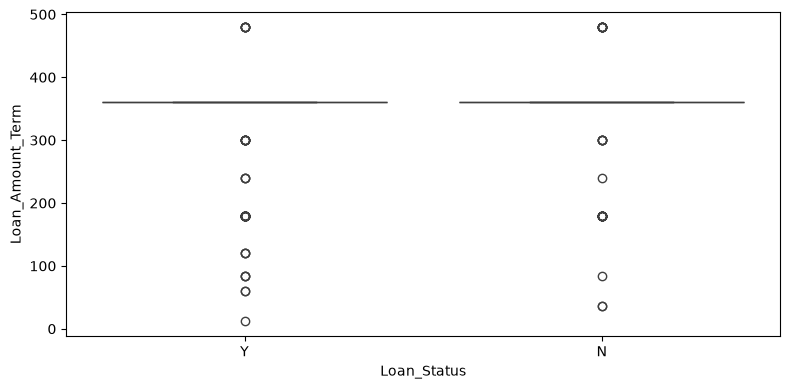

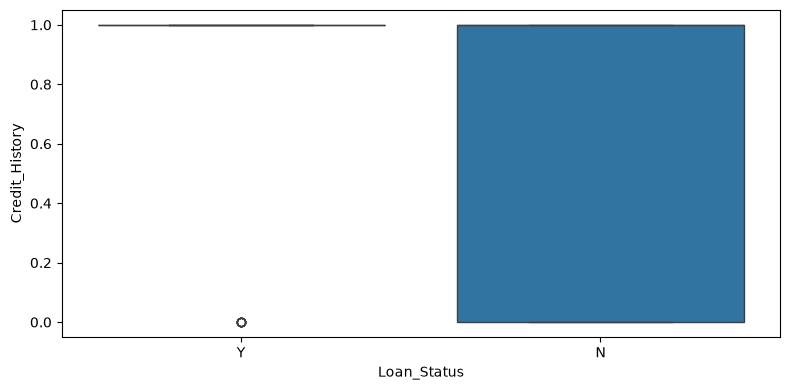

In [38]:
#Numeric feature Vs Loan status

for col in numeric_cols:
    if col != "Loan_Status":
        plt.figure(figsize=(8, 4))
        sns.boxplot(data=df, x="Loan_Status", y=col)
        plt.tight_layout()
        plt.show()

In [39]:
#Statical Analysis

print("Loan Status Distribution (%)")
display((df["Loan_Status"].value_counts(normalize=True) * 100).round(2))

for col in df.select_dtypes(include=["object", "category", "str"]).columns:
    if col not in ["Loan_Status", "Loan_ID"] and df[col].nunique(dropna=True) <= 20:
        print(f"Loan Status Analysis by {col}")
        table = pd.crosstab(
            df[col].fillna("Missing"),
            df["Loan_Status"],
            normalize="index"
        ) * 100
        display(table.round(2))

print("Numeric Features by Loan Status")
display(df.groupby("Loan_Status")[numeric_cols].agg(["mean", "median"]).T)


Loan Status Distribution (%)


Loan_Status
Y    68.73
N    31.27
Name: proportion, dtype: float64

Loan Status Analysis by Gender


Loan_Status,N,Y
Gender,,
Female,33.04,66.96
Male,30.67,69.33
Missing,38.46,61.54


Loan Status Analysis by Married


Loan_Status,N,Y
Married,,
Missing,0.00,100.00
No,37.09,62.91
Yes,28.39,71.61


... (6 outputs left out)

Loan Status Analysis by Property_Area


Loan_Status,N,Y
Property_Area,,
Rural,38.55,61.45
Semiurban,23.18,76.82
Urban,34.16,65.84


Numeric Features by Loan Status


Loan_Status                         N            Y
ApplicantIncome   mean    5446.078125  5384.068720
                  median  3833.500000  3812.500000
CoapplicantIncome mean    1877.807292  1504.516398
                  median   268.000000  1239.500000
LoanAmount        mean     151.220994   144.294404
                  median   129.000000   126.000000
Loan_Amount_Term  mean     344.064516   341.072464
                  median   360.000000   360.000000
Credit_History    mean       0.541899     0.981818
                  median     1.000000     1.000000

In [40]:
#Preprocessing
X = df.drop(columns=["Loan_Status", "Loan_ID"], errors="ignore")
y = df["Loan_Status"]

In [41]:
# determine categorical features and numeric
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

In [42]:
#Train test split
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [43]:
#Numeric pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [44]:
# categorical_pipeline
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [45]:
# ColumnTransformer
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [46]:
#fit_transform
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)


In [47]:
# Check the result
print("Training data shape:", X_train_processed.shape)
print("Validation data shape:", X_val_processed.shape)

print("Number of features:", len(preprocessor.get_feature_names_out()))

Training data shape: (491, 20)
Validation data shape: (123, 20)
Number of features: 20


In [48]:
# Test data
X_test_kaggle = test_df.drop(columns=["Loan_ID"], errors="ignore")

X_test_kaggle = X_test_kaggle.reindex(columns=X.columns)

X_test_processed = preprocessor.transform(X_test_kaggle)

print("Kaggle test data shape:", X_test_processed.shape)

Kaggle test data shape: (367, 20)


In [50]:
#linear Regression
# Convert Target To Numeric 
y_train_num = (y_train == "Y").astype(int)

y_val_num = (y_val == "Y").astype(int)


In [51]:
# Model Creation & Training
lin_reg = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lin_reg.fit(X_train, y_train_num)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Gender','Married','Dependents',...,'Loan_Amount_Term','Credit_History', 'Property_Area']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed 

In [52]:
# Model Prediction
val_score = lin_reg.predict(X_val)

print("RMSE:", round(np.sqrt(mean_squared_error(y_val_num, val_score)), 4))

print("R2:", round(r2_score(y_val_num, val_score), 4))

RMSE: 0.3436
R2: 0.4472


Validation Accuracy: 0.8618
              precision    recall  f1-score   support

           N       0.96      0.58      0.72        38
           Y       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



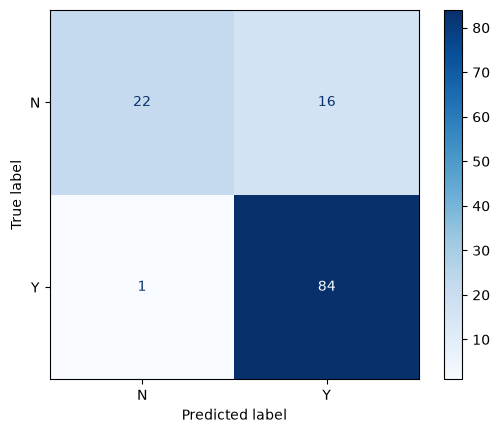

In [53]:
# Classification Evaluation
y_pred = np.where(val_score >= 0.5, "Y", "N")

print("Validation Accuracy:", round(accuracy_score(y_val, y_pred), 4))

print(classification_report(y_val, y_pred))

ConfusionMatrixDisplay(
    confusion_matrix(y_val, y_pred, labels=["N", "Y"]),
    display_labels=["N", "Y"]
).plot(cmap="Blues")

plt.show()

In [54]:
# cross Validation
y_num = (y == "Y").astype(int)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

r2_scores = cross_val_score(
    lin_reg,
    X,
    y_num,
    cv=cv,
    scoring="r2"
)

print("CV R2:", r2_scores.round(3), "| Mean =", r2_scores.mean().round(4))

CV R2: [0.315 0.257 0.283 0.195 0.35 ] | Mean = 0.2801


In [55]:
# Feature Importance Analysis
feat_names = lin_reg.named_steps["preprocessor"].get_feature_names_out()

coefs = pd.Series(
    lin_reg.named_steps["model"].coef_,
    index=feat_names
)

display(coefs.sort_values(key=abs, ascending=False).head(10))

numeric__Credit_History                 0.234491
categorical__Property_Area_Semiurban    0.071186
categorical__Dependents_1              -0.062435
categorical__Property_Area_Rural       -0.049223
categorical__Married_Yes                0.047677
categorical__Married_No                -0.047677
categorical__Dependents_2               0.047285
categorical__Education_Graduate         0.032244
categorical__Education_Not Graduate    -0.032244
numeric__CoapplicantIncome             -0.028496
dtype: float64

In [ ]:
#Test Prediction & Submission
test_score = lin_reg.predict(X_test_kaggle)

test_pred = np.where(test_score >= 0.5, "Y", "N")

submission = pd.DataFrame({
    "Loan_ID": test_df["Loan_ID"],
    "Loan_Status": test_pred
})

submission.to_csv("submission_linear.csv", index=False)

display(submission.head())